# CNN model

In [15]:
import pathlib
import keras
from keras import layers, Model, Input
from keras.utils import image_dataset_from_directory, set_random_seed
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# set random seed to make the model training results reproducible
set_random_seed(29)

<h2>1. Business understanding</h2>

   - Määritellään ratkaistava liiketoimintaongelma (business problem).
   - Tavoitteena on selvittää analyysin päämäärä (goal), vaatimukset (requirements), rajoitteet (constraints) ja odotettu lopputulos (expected outcome).

<h2>2. Data understanding</h2>

   - Kerätään ja tutkitaan saatavilla olevaa dataa.
   - Tässä kartoitetaan datan ominaisuudet, kuten muuttujatyypit ja arvojakaumat, sekä mahdolliset laatuongelmat (quality issues), kuten puuttuvat arvot (missing values), poikkeamat (outliers) ja järjettömät arvot (nonsensical values).

<h2>3. Data preparation</h2>

   - Data siivotaan, muunnetaan ja valitaan olennaiset piirteet (features).
   - Kaikki nämä vaiheet tulee dokumentoida niin tarkasti, että ne ovat myöhemmin täysin toistettavissa.

Load the datasets from the directory. English and Finnish folders are loaded separately in order to get correct class names. `shuffle=False` is used with each dataset to prevent shuffle.  Training dataset is shuffled later in this pipeline. Training datasets are loaded without batch (`batch_size=None`) so that Keras knows the count of the batches later.

In [2]:
# load dataset from directory

data_dir = pathlib.Path("../data/image-samples") # directory with all data

# English datasets
en_train_dataset = image_dataset_from_directory(
    data_dir / "train" / "english",
    image_size=(224, 224),
    batch_size=None,
    shuffle=False)

en_validation_dataset = image_dataset_from_directory(
    data_dir / "validation" / "english",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

en_test_dataset = image_dataset_from_directory(
    data_dir / "test" / "english",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

# Finnish datasets
fi_train_dataset = image_dataset_from_directory(
    data_dir / "train" / "finnish",
    image_size=(224, 224),
    batch_size=None,
    shuffle=False)

fi_validation_dataset = image_dataset_from_directory(
    data_dir / "validation" / "finnish",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

fi_test_dataset = image_dataset_from_directory(
    data_dir / "test" / "finnish",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False)

Found 116 files belonging to 6 classes.
Found 18 files belonging to 6 classes.
Found 18 files belonging to 6 classes.
Found 119 files belonging to 6 classes.
Found 18 files belonging to 6 classes.
Found 18 files belonging to 6 classes.


Let's verify that all of the class names are correct.

In [3]:
en_class_names = en_train_dataset.class_names
fi_class_names = fi_train_dataset.class_names

print("English class names:", en_class_names)
print("Finnish class names:", fi_class_names)

English class names: ['down', 'left', 'right', 'start', 'stop', 'up']
Finnish class names: ['alas', 'oikea', 'paalle', 'pysahdy', 'vasen', 'ylos']


That's correct. We have 6 English and 6 Finnish classes, a total of 12 classes. `image_dataset_from_directory()` has converted the class names into integer values, let's check those for each dataset.

In [4]:
def check_labels(dataset):
    all_labels = np.concatenate([
        # convert unbatched numbers in train dataset into an array
        np.atleast_1d(labels.numpy()) for images, labels in dataset
    ])

    print("Unique labels:", np.unique(all_labels))

print("English train dataset")
check_labels(en_train_dataset)

print("\nFinnish train dataset")
check_labels(fi_train_dataset)

English train dataset
Unique labels: [0 1 2 3 4 5]

Finnish train dataset
Unique labels: [0 1 2 3 4 5]


Now the English and Finnish class indices are overlapping each other. Let's fix the indices of the Finnish classes.

In [5]:
def shift_labels(images, labels):
    return images, labels + 6

fi_train_dataset = fi_train_dataset.map(shift_labels)
fi_validation_dataset = fi_validation_dataset.map(shift_labels)
fi_test_dataset = fi_test_dataset.map(shift_labels)

And then we check the labels again.

In [6]:
print("English")
check_labels(en_train_dataset)

print("\nFinnish")
check_labels(fi_train_dataset)

English
Unique labels: [0 1 2 3 4 5]

Finnish
Unique labels: [ 6  7  8  9 10 11]


Next, we normalize the images. Pixel values are normalized from 0-255 to 0-1 in all six current datasets. `map` applies the normalization function to each image in the given dataset.

In [7]:
def normalize_images(images, labels):
    return images / 255.0, labels

en_train_dataset = en_train_dataset.map(normalize_images)
en_validation_dataset = en_validation_dataset.map(normalize_images)
en_test_dataset = en_test_dataset.map(normalize_images)

fi_train_dataset = fi_train_dataset.map(normalize_images)
fi_validation_dataset = fi_validation_dataset.map(normalize_images)
fi_test_dataset = fi_test_dataset.map(normalize_images)

Then, we combine the English and Finnish datasets. The final datasets are named `train_dataset`, `validation_dataset` and `test_dataset`.  

`train_dataset` is shuffled with a seed, and batched with a batch size of 32. The shuffle buffer is 1000, which is larger than the training dataset so the shuffle is complete. Shuffling mixes English and Finnish samples, so every batch contains classes from both languages. This helps the model learn better. The seed makes the shuffle reproducible. 

In [8]:
train_dataset = (
    en_train_dataset.concatenate(fi_train_dataset)
        .shuffle(1000, seed=29)
        .batch(32)
)

validation_dataset = en_validation_dataset.concatenate(fi_validation_dataset)
test_dataset = en_test_dataset.concatenate(fi_test_dataset)

Let's print all the indices and their corresponding class names.

In [9]:
class_names = en_class_names + fi_class_names

# check that indices are correct
for i, name in enumerate(class_names):
    print(i, "=", name)

0 = down
1 = left
2 = right
3 = start
4 = stop
5 = up
6 = alas
7 = oikea
8 = paalle
9 = pysahdy
10 = vasen
11 = ylos


One more check for each final dataset.

In [10]:
print("Train")
check_labels(train_dataset)
print("\nValidation")
check_labels(validation_dataset)
print("\nTest")
check_labels(test_dataset)

Train
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11]

Validation
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11]

Test
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11]


Now we have indices from 0 to 11 in all of the three final datasets. 

<h2>4. Modeling</h2>

 - Valitaan koneoppimismenetelmä, opetetaan malli ja validoidaan se (validation).
 - Dokumentointiin on sisällytettävä tarkasti valittu menetelmä, käytetyt parametrit sekä mitattu mallin suorituskyky.
 - Millä perusteella tehty valinnat
 - Taulukko on hyvä viestimiseen
 - Ei tarvitse olla yksityiskohtainen, mutta selitetään miksi on päädytty lopputulokseen.

### Model 1

Let's create a base model. It takes images of size 224x224 pixels with 3 color channels as input and alternates between `Conv2D` and `MaxPooling2D` layers.  

The `Conv2D` layers use `ReLU` as activation function and `padding=same`, which adds zeroes around the edges when needed, keeping the size unchanged after convolution. The `MaxPooling2D` makes the feature map smaller. The `GlobalAveragePooling2D` layer transfers the feature maps into one vector. The output layer is a `Dense` layer with `softmax` activation, which provides a propability for each of the 12 classes.

In [11]:
inputs = keras.Input(shape=(224, 224, 3))

x = layers.Conv2D(16, (3,3), activation="relu", padding="same")(inputs)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(32, (3,3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.Conv2D(64, (3,3), activation="relu", padding="same")(x)
x = layers.MaxPooling2D((2, 2))(x)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)
x = layers.Dense(32, activation="relu")(x)

outputs = layers.Dense(12, activation="softmax")(x)

model_01 = Model(inputs=inputs, outputs=outputs, name="model_01_base_model")

# compile model
model_01.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_01.summary()

Model: "model_01_base_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │           396 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,060 (101.80 KB)

 Trainable params: 26,060 (101.80 KB)

 Non-trainable params: 0 (0.00 B)

Let's train the model. `callbacks_01` saves the best-performing model (with best weights) during training, based on the validation loss. The model is saved into a separate file named `01_cnn_base.keras`. The history_01 object stores the training and validation metrics from each epoch.  

`model_01` contains the best weights, and can be used directly in evaluation. `history_01` contains all of the trained epochs, and can be used for plotting the accuracy and loss graphs.

`verbose=1` can be later changed to `verbose=0` to prevent long training logs.

In [12]:
callbacks_01 = [
    keras.callbacks.ModelCheckpoint(
        filepath="./cnn_checkpoints/01_cnn_base.keras",
        save_best_only=True,
        monitor="val_loss"
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    )
]

history_01 = model_01.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks_01,
    verbose=1,
    shuffle=False,
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 5s 257ms/step - accuracy: 0.0468 - loss: 2.4877 - val_accuracy: 0.0833 - val_loss: 2.4849
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 227ms/step - accuracy: 0.0851 - loss: 2.4854 - val_accuracy: 0.0833 - val_loss: 2.4849
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 212ms/step - accuracy: 0.0851 - loss: 2.4846 - val_accuracy: 0.0833 - val_loss: 2.4850
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 210ms/step - accuracy: 0.0979 - loss: 2.4839 - val_accuracy: 0.1111 - val_loss: 2.4851
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 207ms/step - accuracy: 0.0936 - loss: 2.4838 - val_accuracy: 0.0833 - val_loss: 2.4852
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 211ms/step - accuracy: 0.0681 - loss: 2.4831 - val_accuracy: 0.0833 - val_loss: 2.4853
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 221ms/step - accuracy: 0.0681 - loss: 2.4844 - val_accuracy: 0.0833 - val_loss: 2.4853
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 213ms/step - accuracy: 0.0936 - loss: 2.4829 - val_accuracy: 0.0833 - val_loss:

Let's print the validation metrics, and plot the graphs.

Best epoch: 2
Training accuracy: 0.0851
Validation accuracy: 0.0833
Training loss: 2.4854
Validation loss: 2.4849


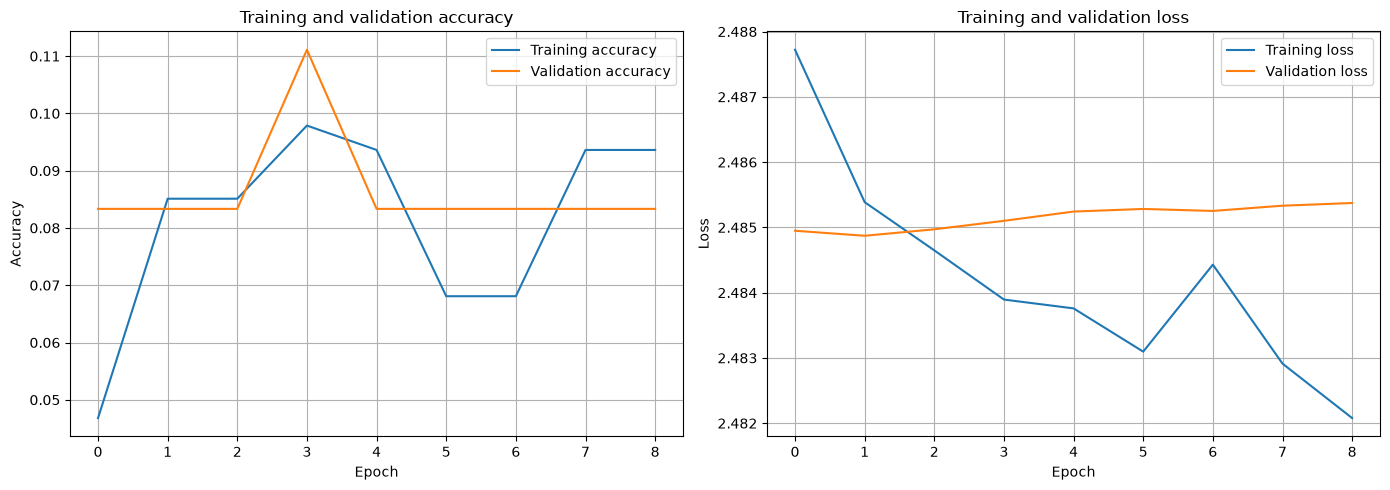

In [16]:
# print best epoch results
def display_validation_results(history):
    
    # find the best epoch based on validation loss
    best_epoch = np.argmin(history.history['val_loss'])
    
    print(f"Best epoch: {best_epoch + 1}")
    print(f"Training accuracy: {history.history['accuracy'][best_epoch]:.4f}")
    print(f"Validation accuracy: {history.history['val_accuracy'][best_epoch]:.4f}")
    print(f"Training loss: {history.history['loss'][best_epoch]:.4f}")
    print(f"Validation loss: {history.history['val_loss'][best_epoch]:.4f}")

def plot_training_history(history):
    # get values from history
    accuracy = history.history['accuracy']
    val_accuracy = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    # two graphs
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 5))

    # accuracy
    ax0.plot(accuracy, label='Training accuracy')
    ax0.plot(val_accuracy, label='Validation accuracy')
    ax0.set_xlabel('Epoch')
    ax0.set_ylabel('Accuracy')
    ax0.set_title('Training and validation accuracy')
    ax0.legend()
    ax0.grid()
    
    # loss
    ax1.plot(loss, label='Training loss')
    ax1.plot(val_loss, label='Validation loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Training and validation loss')
    ax1.legend()
    ax1.grid()

    plt.tight_layout()
    plt.show()

display_validation_results(history_01)
plot_training_history(history_01)

<h2>5. Evaluation</h2>

 - Arvioidaan mallin todellinen onnistuminen.
 - Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).<br>
 - Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.

<h2>6. Deployment</h2>

- Malli viedään käytäntöön (deployment).
- Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.